# 06 - Cross-dataset evaluation on CSE-CIC-IDS2018

The models trained on CIC-IDS2017, unchanged, on a dataset they have never seen. Nothing is retrained.

This notebook calls the same code as `python -m backend.evaluate_ids2018` (`evaluate` there and the functions in `src/ids2018.py`), then checks that its numbers match the saved `reports/ids2018/metrics.json`.

**Data:** every CSV in `data/raw/ids2018/`. Takes several minutes and a few GB of memory.

**Citation:** Sharafaldin, Lashkari & Ghorbani, "Toward Generating a New Intrusion Detection Dataset and Intrusion Traffic Characterization", ICISSP 2018. https://registry.opendata.aws/cse-cic-ids2018

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from backend.evaluate_ids2018 import OUT_DIR, comparison_table, confusion_png, evaluate
from ids2018 import COLUMN_MAP, LABEL_MAP

print(f"{len(COLUMN_MAP)} renamed columns, {len(LABEL_MAP)} mapped labels")

18 renamed columns, 8 mapped labels


## Run the evaluation

This loads every file, cleans it like the 2017 data, drops duplicates, takes the stratified sample and runs the real `CyberSentryPipeline` on the 32 features only. It fails loudly if a feature doesn't map.

In [2]:
metrics, unique, sample, results = evaluate(ROOT)
print(f"{len(unique):,} distinct flows, {len(sample):,} in the sample")

2,644,361 distinct flows, 100,108 in the sample


## What dropping duplicates and sampling left

In [3]:
d = metrics["data"]
pd.DataFrame({"after cleaning": d["rows_after_cleaning"], "after dropping duplicates": d["rows_after_dropping_duplicates"],
              "in sample": d["rows_in_sample"]})

,after cleaning,after dropping duplicates,in sample
Benign,2229747,2059880,20000
Bot,286191,144535,20000
DDOS attack-HOIC,686012,198861,18270
DDOS attack-LOIC-UDP,1730,1730,1730
DoS attacks-Hulk,461912,145199,20000
DoS attacks-SlowHTTPTest,139890,55,55
FTP-BruteForce,193354,53,53
SSH-Bruteforce,187589,94048,20000


## Results, next to the 2017 test split

In [4]:
display(Markdown(comparison_table(metrics)))

# CIC-IDS2017 vs CSE-CIC-IDS2018

Same models, not retrained. 2017 is the held-out test split. The 2018 sample caps each class at 20,000 rows, so about 80.02% of it is attacks. "All 2018 rows" uses every distinct flow, where 22.10% are attacks.

## Stage 1: attack vs benign

| Metric | 2017 test | 2018 sample | All 2018 rows |
|---|---:|---:|---:|
| Accuracy | 99.92% | 24.74% | 79.16% |
| Precision | 99.54% | 99.92% | 98.73% |
| Recall | 99.96% | 5.96% | 5.79% |
| F1 | 99.75% | 11.25% | 10.93% |
| FPR | 0.09% | 0.02% | 0.02% |
| FNR | 0.04% | 94.04% | 94.21% |
| ROC-AUC | 100.00% | 81.84% | 74.34% |

## Full pipeline: which attack

| Metric | 2017 test | 2018 sample |
|---|---:|---:|
| Accuracy | 99.89% | 20.14% |
| Macro-F1 | 95.33% (13 classes) | 5.12% (7 classes) |

## Per class

| Class | Rows | Precision | Recall | F1 | 2017 test recall | 2017 test F1 |
|---|---:|---:|---:|---:|---:|---:|
| BENIGN | 20,000 | 20.63% | 99.98% | 34.20% | 99.91% | 99.95% |
| Bot | 20,000 | 0.00% | 0.00% | 0.00% | 91.44% | 82.03% |
| DDoS | 20,000 | 0.00% | 0.00% | 0.00% | 99.98% | 99.98% |
| DoS Hulk | 20,000 | 99.32% | 0.73% | 1.44% | 99.78% | 99.81% |
| DoS Slowhttptest | 55 | 0.00% | 0.00% | 0.00% | 98.72% | 98.29% |
| FTP-Patator | 53 | 0.00% | 0.00% | 0.00% | 99.78% | 99.50% |
| SSH-Patator | 20,000 | 95.65% | 0.11% | 0.22% | 98.55% | 99.06% |

## Per day file, 2018 sample

| Day | Rows | Stage 1 recall | Stage 1 FPR | ROC-AUC | Pipeline accuracy | Macro-F1 |
|---|---:|---:|---:|---:|---:|---:|
| 02-14-2018 | 25,053 | 0.35% | 0.06% | 90.98% | 20.03% | 11.19% |
| 02-16-2018 | 25,055 | 23.45% | 0.00% | 99.88% | 20.53% | 12.84% |
| 02-21-2018 | 25,000 | 0.00% | 0.00% | 22.41% | 20.00% | 16.67% |
| 03-02-2018 | 25,000 | 0.00% | 0.02% | 89.91% | 20.00% | 16.66% |


## Confusion matrix

What each 2018 class gets predicted as, including classes like PortScan that don't exist in the 2018 files.

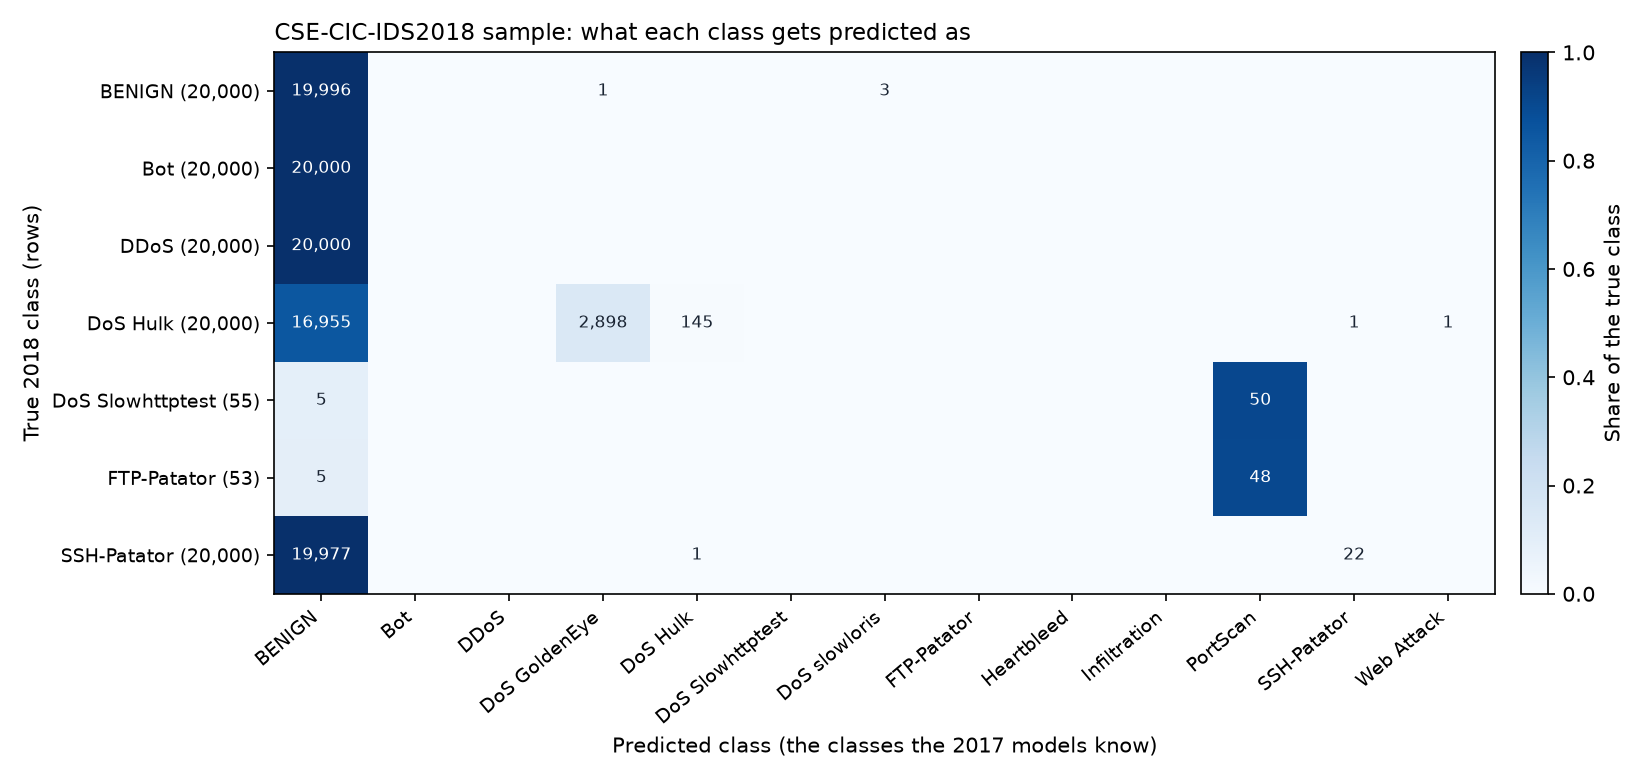

In [5]:
png = ROOT / "reports" / "ids2018" / "confusion_matrix.png"
confusion_png(metrics, png)
display(Image(filename=str(png)))

## Control: the same code on the 2017 test split

If the metric code were broken, this would not reproduce the macro-F1 saved at training time.

In [6]:
old = metrics["cic_ids2017_test"]
print("saved at training time:", round(old["pipeline_macro_f1"], 4))
print("recomputed here:       ", round(old["multiclass_recomputed"]["macro_f1"], 4))
pd.DataFrame(old["multiclass_recomputed"]["per_class"]).set_index("class").round(3)

saved at training time: 0.9533
recomputed here:        0.9533


,precision,recall,f1,support
class,,,,
BENIGN,1.000,0.999,0.999,310867
Bot,0.744,0.914,0.820,292
DDoS,1.000,1.000,1.000,19202
DoS GoldenEye,0.954,1.000,0.976,1543
DoS Hulk,0.998,0.998,0.998,25927
DoS Slowhttptest,0.979,0.987,0.983,784
DoS slowloris,0.995,0.981,0.988,808
FTP-Patator,0.992,0.998,0.995,890
Heartbleed,1.000,1.000,1.000,1


## Why: how far features moved

Medians per class in both datasets, for the features that moved most by class.

In [7]:
rows = [{"class": c, "feature": f, **v} for c, fs in metrics["class_feature_medians"].items() for f, v in fs.items()]
shift = pd.DataFrame(rows)
shift["changed"] = shift["2017"] != shift["2018"]
shift[shift["feature"].isin(["Destination Port", "Init_Win_bytes_backward", "Init_Win_bytes_forward", "Flow Duration", "Packet Length Mean"])] \
    .pivot(index="class", columns="feature", values=["2017", "2018"]).round(1)

2017                                        \
feature          Destination Port Flow Duration Init_Win_bytes_backward   
class                                                                     
BENIGN                       80.0       46090.0                    -1.0   
Bot                        8080.0       71810.5                   237.0   
DDoS                         80.0     1888734.5                   229.0   
DoS Hulk                     80.0    86417490.0                   235.0   
DoS Slowhttptest             80.0    63122514.0                    -1.0   
FTP-Patator                  21.0     8653363.0                   227.0   
SSH-Patator                  22.0    11990970.0                   247.0   

                                                                       2018  \
feature          Init_Win_bytes_forward Packet Length Mean Destination Port   
class                                                                         
BENIGN                            122.0               61.6          41162.0   
Bot                              8192.0                6.0           8080.0   
DDoS                              256.0              833.5             80.0   
DoS Hulk                          251.0              852.6             80.0   
DoS Slowhttptest                29200.0                0.0             21.0   
FTP-Patator                     29200.0               11.6             21.0   
SSH-Patator                     29200.0               88.0             22.0   

                                                                               \
feature          Flow Duration Init_Win_bytes_backward Init_Win_bytes_forward   
class                                                                           
BENIGN                290444.5                   211.0                 8192.0   
Bot                    10913.0                   219.0                 8192.0   
DDoS                   12599.0                   219.0                65535.0   
DoS Hulk               50929.0                    -1.0                  225.0   
DoS Slowhttptest          28.0                     0.0                26883.0   
FTP-Patator               27.0                     0.0                26883.0   
SSH-Patator           374646.0                   230.0                26883.0   

                                     
feature          Packet Length Mean  
class                                
BENIGN                        142.9  
Bot                            56.9  
DDoS                          152.9  
DoS Hulk                        0.0  
DoS Slowhttptest                0.0  
FTP-Patator                     0.0  
SSH-Patator                   102.4

## Same numbers as the script

In [8]:
saved = json.load(open(OUT_DIR / "metrics.json"))
assert metrics == saved, "notebook and script disagree"
print("metrics.json matches this notebook exactly")

metrics.json matches this notebook exactly


See `reports/ids2018/summary.md` for what generalised, what didn't, and likely reasons.